# Combined paper figures from saved results

Run All to load the three dataset exports and produce:
1. A three-panel spatial–multivariate performance plane.
2. A two-panel paired continuity boxplot (CMiO deposits and North Batten drillholes), with Holm-adjusted significance and no dots.
3. A three-panel evaluation-scale diagnostic at $k_e=5,10,20,40$, reusing principal $k=10$ partitions.
4. **Table 3: Principal k = 10 benchmark across 30 algorithm seeds.**

This notebook only reads exported CSV/JSON data. It does not refit embeddings or cluster assignments. The evaluation-scale section only recomputes raw-coordinate evaluation neighbours and spatial contiguity. Each figure has its own cell and caption. Set `SAVE_OUTPUTS=True` to save PDF/600-dpi PNG figures and CSV/HTML/LaTeX tables in `results/combined_paper_figures/`. The default displays outputs inline without writing figure files.

In [25]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, FuncFormatter
from IPython.display import display, HTML
from matplotlib_inline.backend_inline import set_matplotlib_formats


def find_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'results' / 'notebook_exports').is_dir():
            return candidate
        nested = candidate / 'sc-pacmap-reproducibility'
        if (nested / 'results' / 'notebook_exports').is_dir():
            return nested
    raise FileNotFoundError('Cannot find results/notebook_exports; run the three export notebooks first.')

ROOT = find_root()
EXPORT_ROOT = ROOT / 'results' / 'notebook_exports'
OUTPUT_ROOT = ROOT / 'results' / 'combined_paper_figures'
SAVE_OUTPUTS = False
DATASETS = ('cmio', 'north_batten', 'synthetic')
PRINCIPAL_K = 10  # Fitting neighbourhood k, not K-means cluster count K.
PRIMARY = 'SC-PaCMAP full graph'
NEIGHBOR_MARKERS = {10: 'o', 15: '^', 20: 's'}
SHOW_PLANE_MEDIANS = True

set_matplotlib_formats('retina')
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'figure.dpi': 600, 'savefig.dpi': 600,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': .6, 'axes.edgecolor': '#444444',
    'axes.grid': False, 'grid.color': '#E4E4E4', 'grid.linewidth': .5,
    'legend.frameon': False, 'lines.linewidth': 1.2,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

def show_paper_figure(fig, name):
    if SAVE_OUTPUTS:
        OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_ROOT / f'{name}.pdf', bbox_inches='tight')
        fig.savefig(OUTPUT_ROOT / f'{name}.png', dpi=600, bbox_inches='tight')
    display(fig)
    plt.close(fig)

print(f'Reading saved results: {EXPORT_ROOT}')


Reading saved results: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports


## Load and check the saved data
Method colours come from the exports. The shared legend uses “coordinates” for the XYZ inputs in the real datasets and XY inputs in Synthetic. All active benchmarks, including the three ClustGeo variants, are retained.

In [26]:
def read_table(dataset, section, filename):
    path = EXPORT_ROOT / dataset / section / filename
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}. Rerun its export cell in the source results notebook.')
    return pd.read_csv(path)


def canonical_method(method):
    return method.replace(' + XYZ', ' + coordinates').replace(' + XY', ' + coordinates')


def short_label(method):
    if method == PRIMARY:
        return 'SC-PaCMAP'
    return method.replace('PaCMAP feature-only + ClustGeo', 'PaCMAP + ClustGeo')


def check_seeds(frame, keys, expected, context):
    if frame.duplicated(keys + ['seed']).any():
        raise ValueError(f'{context}: duplicate paired seed records.')
    for group, part in frame.groupby(keys, dropna=False):
        if sorted(part.seed.tolist()) != list(expected):
            raise ValueError(f'{context}: {group} does not contain the expected 30 seeds.')

metadata, planes, seed_metrics = {}, {}, {}
COLORS, METHOD_ORDER = {}, []
for dataset in DATASETS:
    path = EXPORT_ROOT / dataset / 'performance_plane' / 'metadata.json'
    metadata[dataset] = json.loads(path.read_text(encoding='utf-8'))
    meta = metadata[dataset]
    if meta['seeds'] != list(range(30)):
        raise ValueError(f'{dataset}: expected seeds 0 through 29.')
    for raw_method in meta['methods']:
        method = canonical_method(raw_method)
        color = meta['method_colors'][raw_method]
        if method in COLORS and COLORS[method].lower() != color.lower():
            raise ValueError(f'Exported method colours disagree for {method}.')
        COLORS[method] = color
        if method not in METHOD_ORDER:
            METHOD_ORDER.append(method)

    plane = read_table(dataset, 'performance_plane', 'seed_points.csv')
    plane['method'] = plane.method.map(canonical_method)
    if set(plane.method) != set(map(canonical_method, meta['methods'])):
        raise ValueError(f'{dataset}: performance-plane methods disagree with metadata.')
    if not plane.K.eq(meta['K_reference']).all():
        raise ValueError(f'{dataset}: performance plane must use the reference class count.')
    check_seeds(plane, ['method', 'n_neighbors'], meta['seeds'], dataset + ' plane')
    if not np.isfinite(plane[['spatial_contiguity', 'multivariate_delineation']]).all().all():
        raise ValueError(f'{dataset}: missing performance-plane scores.')
    planes[dataset] = plane

    metrics = read_table(dataset, 'evaluation_curves', 'seed_metrics.csv')
    metrics['method'] = metrics.method.map(canonical_method)
    check_seeds(metrics, ['method', 'n_neighbors', 'K'], meta['seeds'], dataset + ' metrics')
    metrics['spatial_contiguity'] = 100 * (
        1 - metrics.H_per_sample / np.log(np.minimum(metrics.K, meta['evaluation_neighbors'])))
    metrics['multivariate_delineation'] = 100 * (1 - metrics.WCSS_TSS)
    seed_metrics[dataset] = metrics


print('Validated three datasets, consistent colours, and 30 seeds per result group.')


def compact_label(method):
    if method == PRIMARY:
        return 'SC-PaCMAP'
    if method.startswith('PaCMAP feature-only + ClustGeo'):
        alpha = method.split('alpha=')[1].rstrip(')')
        return f'ClustGeo, $\\alpha={alpha}$'
    return method.replace(' + coordinates', ' + coords').replace('PaCMAP feature-only', 'PaCMAP features')


def panel_letter(ax, index):
    ax.text(0, 1.025, f'({chr(97 + index)})', transform=ax.transAxes,
            fontsize=8, fontweight='bold', va='bottom')


def compact_method_handles():
    return [Line2D([], [], linestyle='None', marker='o', markersize=3,
                   color=COLORS[m], label=compact_label(m)) for m in METHOD_ORDER]


Validated three datasets, consistent colours, and 30 seeds per result group.


## Figure: performance plane across three datasets

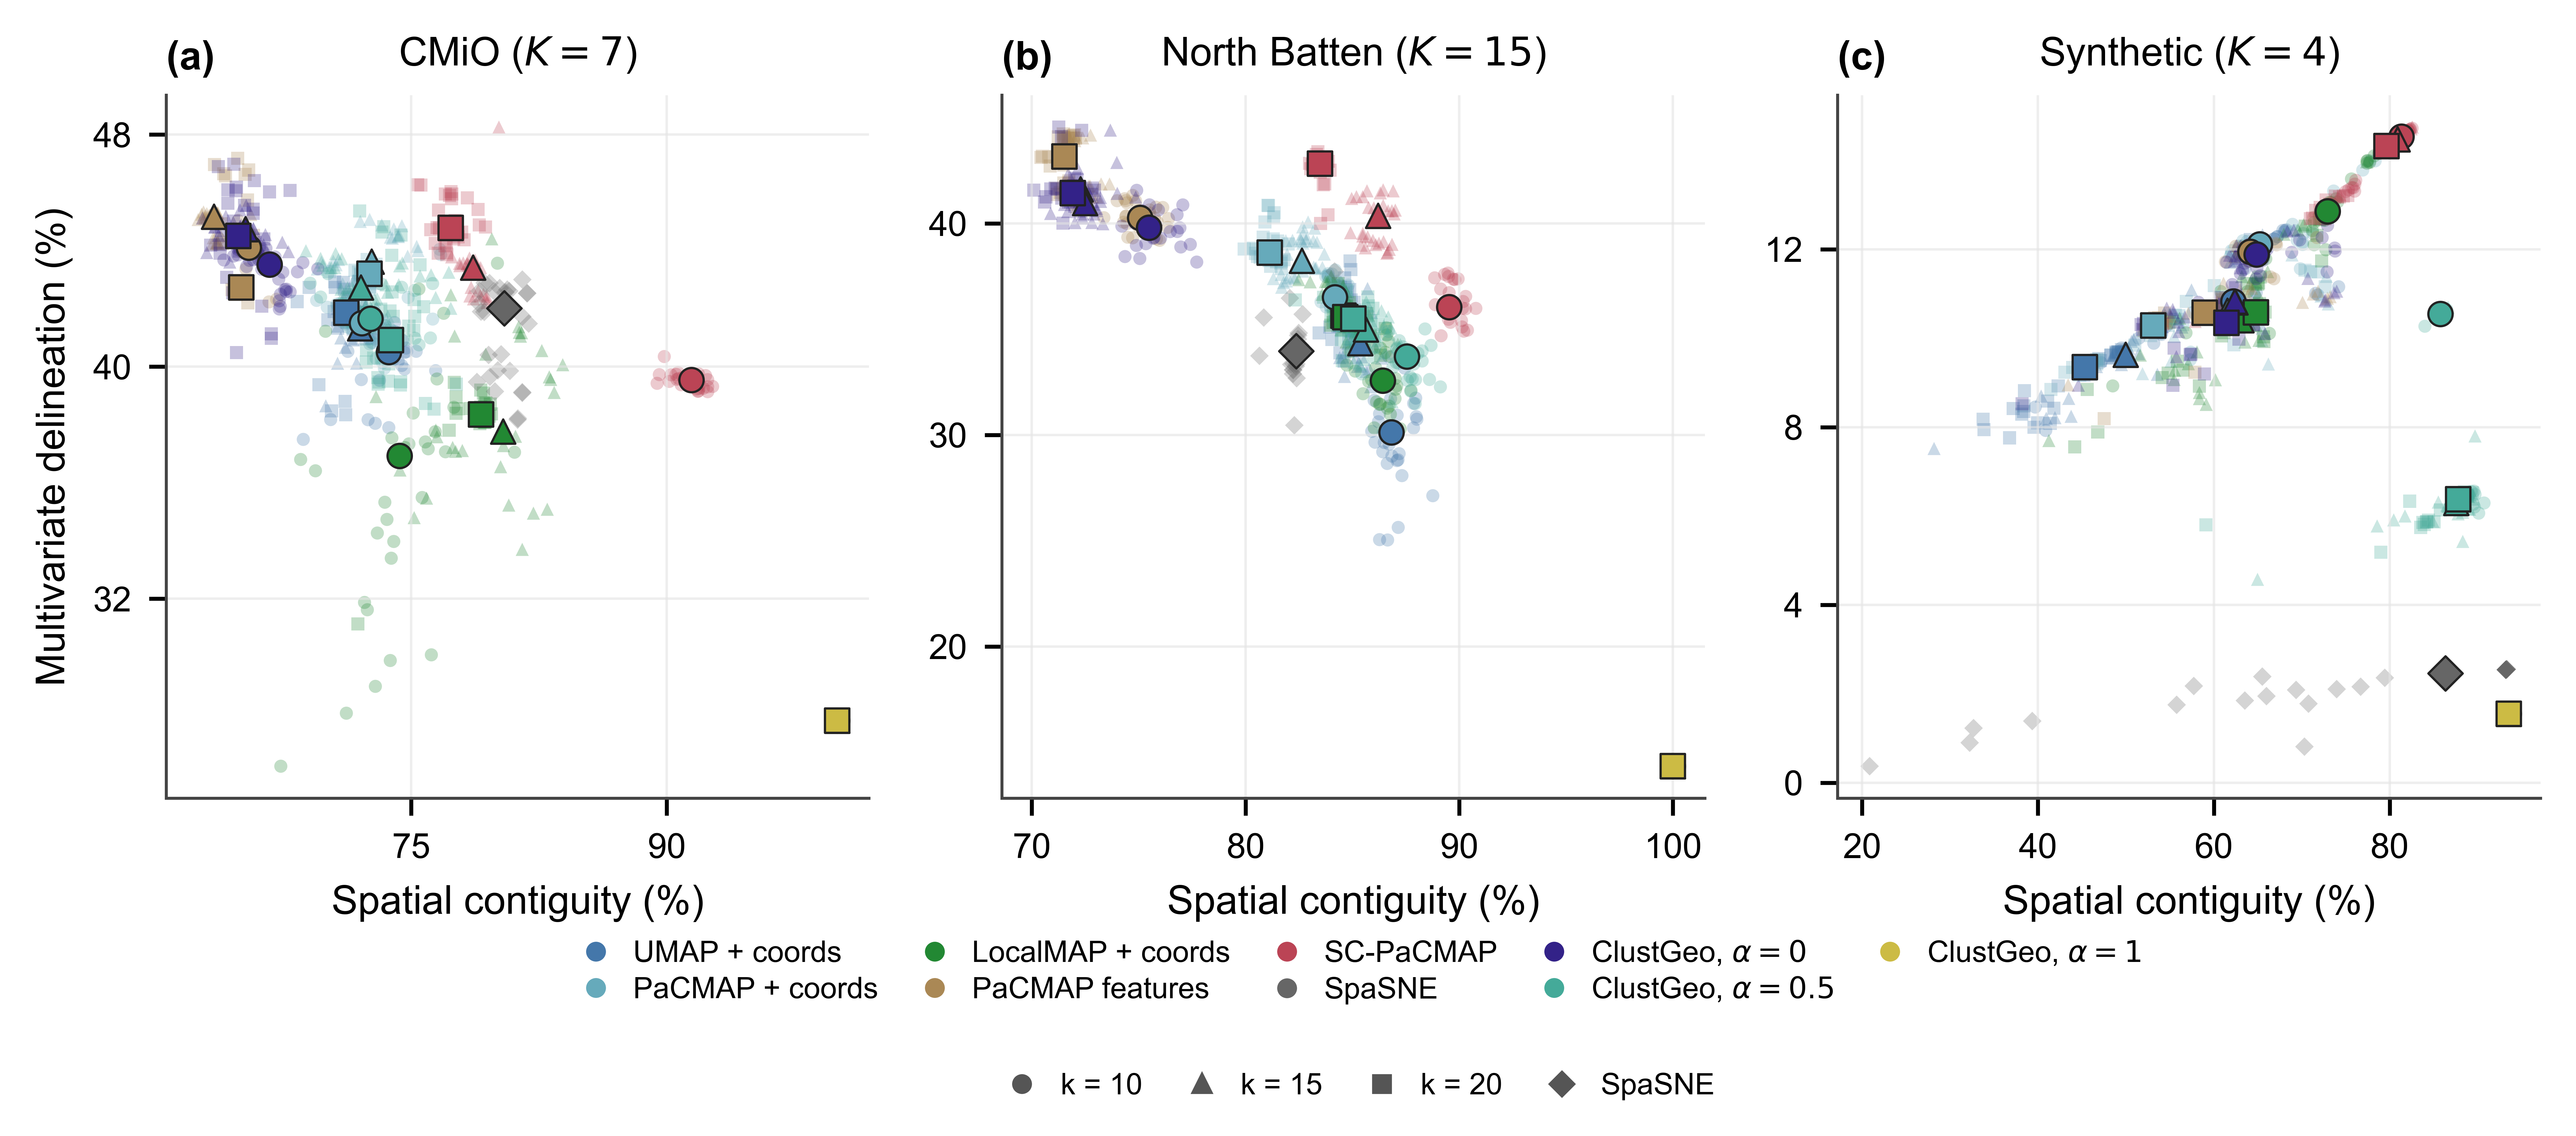

In [27]:
fig = plt.figure(figsize=(7.1, 3.05), layout='constrained')
grid = fig.add_gridspec(2, 3, height_ratios=[1, .18])
axes = [fig.add_subplot(grid[0, i]) for i in range(3)]
legend_ax = fig.add_subplot(grid[1, :])
legend_ax.set_axis_off()
for panel, (ax, dataset) in enumerate(zip(axes, DATASETS)):
    frame = planes[dataset]
    for method in METHOD_ORDER:
        part = frame[frame.method == method]
        for neighbors, group in part.groupby('n_neighbors'):
            marker = 'D' if method == 'SpaSNE' else NEIGHBOR_MARKERS[int(neighbors)]
            ax.scatter(group.spatial_contiguity, group.multivariate_delineation,
                       color=COLORS[method], marker=marker, s=7, alpha=.28,
                       edgecolors='none', rasterized=True)
            if SHOW_PLANE_MEDIANS:
                median = group[['spatial_contiguity', 'multivariate_delineation']].median()
                ax.scatter(median.spatial_contiguity, median.multivariate_delineation,
                           color=COLORS[method], marker=marker, s=24,
                           edgecolors='#222222', linewidths=.45, zorder=4)
    ax.set_box_aspect(1)
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.grid(alpha=.6)
    ax.set_xlabel('Spatial contiguity (%)')
    panel_letter(ax, panel)
    ax.set_title(f"{metadata[dataset]['dataset_title']} ($K={metadata[dataset]['K_reference']}$)",
                 fontsize=8, pad=6)
axes[0].set_ylabel('Multivariate delineation (%)')
method_key = legend_ax.legend(handles=compact_method_handles(), loc='upper center',
                              bbox_to_anchor=(.5, 1.15), ncol=5, fontsize=6,
                              columnspacing=.9, handletextpad=.25,
                              labelspacing=.3, borderpad=0)
legend_ax.add_artist(method_key)
neighborhood_handles = [Line2D([], [], color='#555555', marker=shape,
                               linestyle='None', markersize=3, label=f'k = {k}')
                        for k, shape in NEIGHBOR_MARKERS.items()]
neighborhood_handles.append(Line2D([], [], color='#555555', marker='D',
                                   linestyle='None', markersize=3, label='SpaSNE'))
legend_ax.legend(handles=neighborhood_handles, loc='lower center',
                 bbox_to_anchor=(.5, -.25), ncol=4, fontsize=6,
                 columnspacing=1., handletextpad=.3, borderpad=0)
show_paper_figure(fig, 'performance_plane_three_datasets')


**Figure caption.** (a) CMiO, (b) North Batten and (c) Synthetic, at their reference class counts $K=7,15,4$. Colours identify methods consistently across figures; circles, triangles and squares identify fitting neighbourhoods $k=10,15,20$. SpaSNE uses diamonds and is shown once per seed because its fixed-perplexity results are reused across neighbourhood settings. Small transparent points are algorithm seeds; larger outlined markers are coordinate-wise medians across 30 seeds. The geographic evaluation neighbourhood is fixed at 10. Axis limits adapt to each dataset. These are seed variations on fixed datasets.

## Figure: paired cross-deposit and cross-drillhole continuity
Only horizontal boxes, median lines and range whiskers are shown. Outlier dots and seed dots are disabled. Stars use the exported Holm-adjusted one-sided paired Wilcoxon tests across all active comparators within each dataset.

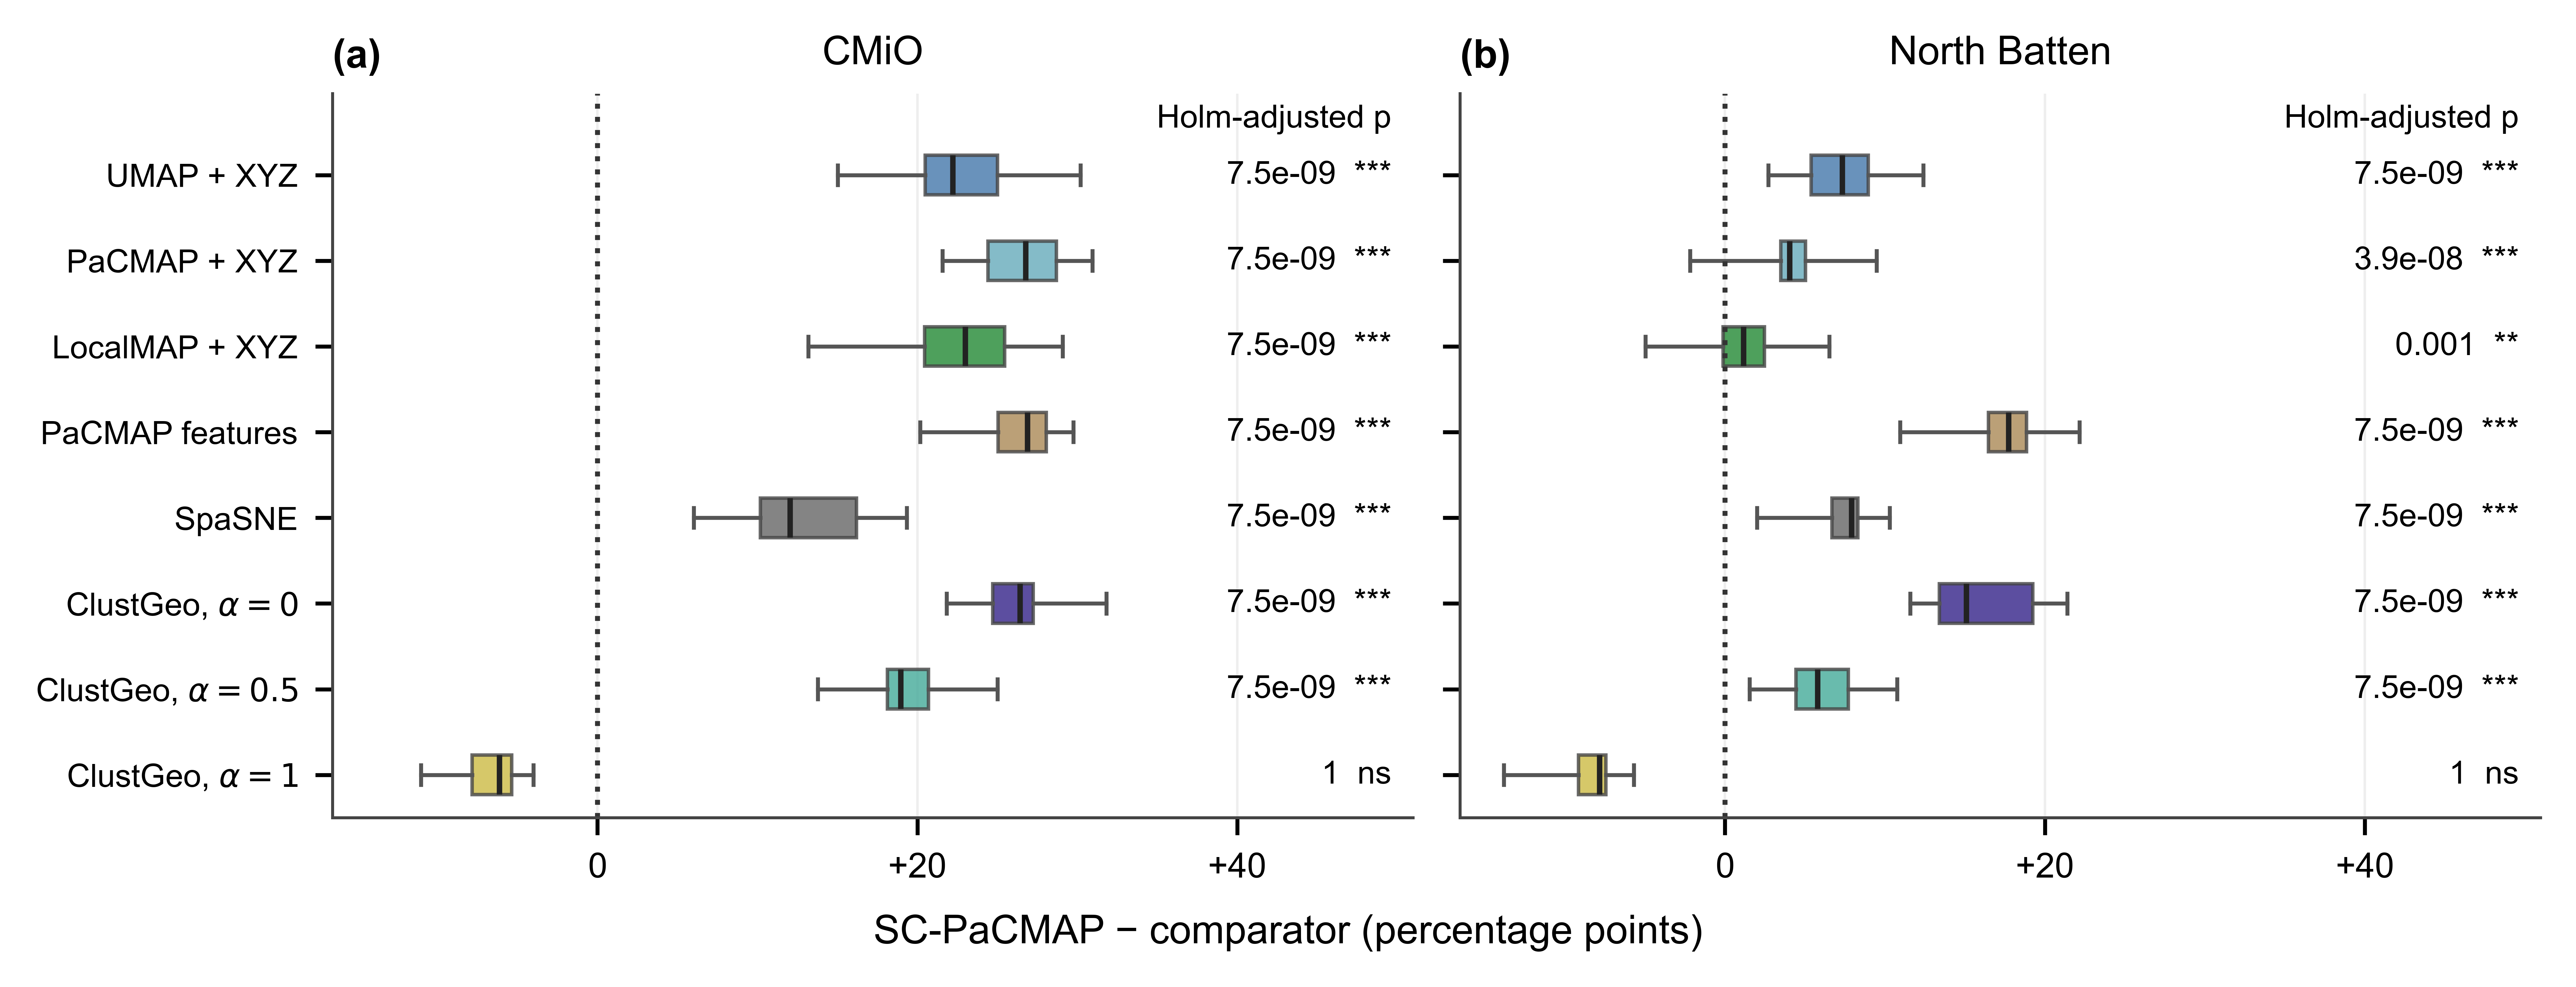

In [28]:
continuity = {}
for dataset in DATASETS[:2]:
    delta = read_table(dataset, 'cross_group_plot', 'paired_differences.csv').set_index('seed')
    delta.columns = [canonical_method(m) for m in delta.columns]
    tests = read_table(dataset, 'cross_group_plot', 'holm_tests.csv')
    tests['comparator'] = tests.comparator.map(canonical_method)
    if not tests.paired_seeds.eq(30).all() or not tests.primary.eq(PRIMARY).all():
        raise ValueError(f'{dataset}: continuity tests do not describe the expected primary and 30 pairs.')
    ordered = tests.sort_values('p_greater')
    expected_holm = np.minimum(1., np.maximum.accumulate(
        ordered.p_greater.to_numpy() * np.arange(len(ordered), 0, -1)))
    np.testing.assert_allclose(ordered.holm_p, expected_holm, atol=1e-12)
    tests = tests.set_index('comparator')
    scores = read_table(dataset, 'cross_group_continuity', 'seed_scores.csv')
    scores['method'] = scores.method.map(canonical_method)
    scores = scores.pivot(index='seed', columns='method', values='cross_group_continuity')
    comparators = [m for m in METHOD_ORDER if m != PRIMARY and m in scores.columns]
    if set(delta.columns) != set(comparators) or set(tests.index) != set(comparators):
        raise ValueError(f'{dataset}: continuity files have inconsistent comparators.')
    if delta.index.tolist() != metadata[dataset]['seeds'] or scores.index.tolist() != metadata[dataset]['seeds']:
        raise ValueError(f'{dataset}: continuity requires 30 matched seeds.')
    delta = delta[comparators]
    expected = scores[comparators].rsub(scores[PRIMARY], axis=0)
    np.testing.assert_allclose(delta, expected, atol=1e-10, rtol=1e-10)
    if not np.isfinite(delta.to_numpy()).all() or not tests.holm_p.between(0, 1).all():
        raise ValueError(f'{dataset}: invalid differences or Holm p-values.')
    np.testing.assert_allclose(delta.median(), tests.loc[comparators, 'median_difference'], atol=1e-10)
    continuity[dataset] = (delta, tests, comparators)

def significance(p):
    return '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'ns'

low = min(0., *(item[0].min().min() for item in continuity.values()))
high = max(0., *(item[0].max().max() for item in continuity.values()))
span = max(high - low, 1.)
fig, axes = plt.subplots(1, 2, figsize=(7.1, 2.65), layout='constrained', sharex=True, sharey=True)
for panel, (ax, dataset) in enumerate(zip(axes, DATASETS[:2])):
    delta, tests, comparators = continuity[dataset]
    artists = ax.boxplot([delta[m].to_numpy() for m in comparators],
                        vert=False, positions=range(len(comparators)), widths=.46,
                        whis=(0, 100), showfliers=False, patch_artist=True,
                        boxprops={'edgecolor': '#444444', 'linewidth': .7},
                        medianprops={'color': '#222222', 'linewidth': 1.1},
                        whiskerprops={'color': '#555555', 'linewidth': .8},
                        capprops={'color': '#555555', 'linewidth': .8})
    for row, (method, box) in enumerate(zip(comparators, artists['boxes'])):
        box.set_facecolor(COLORS[method])
        box.set_alpha(.8)
        holm_p = tests.loc[method, 'holm_p']
        ax.text(.98, row, f'{holm_p:.2g}  {significance(holm_p)}',
                transform=ax.get_yaxis_transform(), ha='right', va='center',
                fontsize=6.5)
    labels = [compact_label(m).replace(' + coords', ' + XYZ') for m in comparators]
    ax.set_yticks(range(len(comparators)), labels, fontsize=6.5)
    ax.set_ylim(len(comparators) - .5, -.95)
    ax.set_xlim(low - .06 * span, high + .42 * span)
    ax.axvline(0, color='#333333', linestyle=':', linewidth=1.)
    ax.grid(axis='x', alpha=.6)
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:+g}' if x else '0'))
    panel_letter(ax, panel)
    ax.set_title(metadata[dataset]['dataset_title'], fontsize=8, pad=6)
    ax.text(.98, -.65, 'Holm-adjusted p', transform=ax.get_yaxis_transform(),
            ha='right', va='center', fontsize=6.5)
fig.supxlabel('SC-PaCMAP − comparator (percentage points)', fontsize=8)
show_paper_figure(fig, 'paired_cross_group_continuity_two_datasets')


**Figure caption.** Paired SC-PaCMAP minus comparator continuity across 30 matched algorithm seeds: (a) CMiO after excluding each sample's own deposit; (b) North Batten after excluding its own drillhole. Boxes show the interquartile range, central lines the medians, and whiskers the full seed range. No dots are shown. The zero reference line marks equal performance; positive differences favour SC-PaCMAP. Colours match the performance plane. Labels use Holm-adjusted p-values: * p < 0.05, ** p < 0.01, *** p < 0.001; ns otherwise. Seed ranges describe algorithm variability, not confidence intervals or independent geological replication. These are full-data diagnostics, not held-out-group predictions.

## Figure: evaluation-scale diagnostic
Using partitions from the principal fitting neighbourhood $k=10$ at each dataset's reference class count, recompute spatial contiguity for raw-coordinate evaluation neighbourhoods $k_e \in \{5,10,20,40\}$. Embeddings and cluster assignments remain fixed. All benchmarks use the same method colours as the performance plane.

In [29]:
from sklearn.neighbors import NearestNeighbors

EVALUATION_NEIGHBORS = (5, 10, 20, 40)


def spatial_contiguity_for_neighbors(labels, neighbors, cluster_count):
    # Count each focal sample's neighbours by cluster in one vectorized pass.
    n_samples, k_e = neighbors.shape
    labels = np.asarray(labels, dtype=int)
    if labels.shape != (n_samples,) or labels.min() < 0 or labels.max() >= cluster_count:
        raise ValueError('Saved cluster labels do not match sample count or reference K.')
    offsets = np.arange(n_samples, dtype=np.int64)[:, None] * cluster_count
    counts = np.bincount((labels[neighbors] + offsets).ravel(),
                         minlength=n_samples * cluster_count).reshape(n_samples, cluster_count)
    probabilities = counts / k_e
    logs = np.zeros_like(probabilities)
    np.log(probabilities, out=logs, where=probabilities > 0)
    h_per_sample = -(probabilities * logs).sum(axis=1).mean()
    return 100 * (1 - h_per_sample / np.log(min(cluster_count, k_e)))


scale_rows = []
for dataset in DATASETS:
    meta = metadata[dataset]
    cluster_count = meta['K_reference']
    with np.load(EXPORT_ROOT / dataset / 'data_walkthrough' / 'arrays.npz',
                 allow_pickle=False) as archive:
        coordinates = archive['coordinates'].copy()
        principal_neighbors = archive['spatial_neighbors'].copy()
    if coordinates.shape[0] != meta['sample_count'] or coordinates.shape[0] <= max(EVALUATION_NEIGHBORS):
        raise ValueError(f'{dataset}: coordinate array has an unexpected sample count.')
    # Retain the exact saved k_e=10 neighbourhood, including its tie ordering.
    neighbors_by_scale = {
        k_e: (principal_neighbors if k_e == meta['evaluation_neighbors'] else
              NearestNeighbors(n_neighbors=k_e + 1, n_jobs=1).fit(coordinates)
              .kneighbors(coordinates, return_distance=False)[:, 1:])
        for k_e in EVALUATION_NEIGHBORS
    }
    index = json.loads((EXPORT_ROOT / dataset / 'benchmark' / 'clusters_index.json').read_text(encoding='utf-8'))
    entries = [item for item in index if item['n_neighbors'] == PRINCIPAL_K
               and item['K'] == cluster_count]
    with np.load(EXPORT_ROOT / dataset / 'benchmark' / 'clusters.npz', allow_pickle=False) as archive:
        for item in entries:
            method = canonical_method(item['method'])
            if method not in METHOD_ORDER:
                continue
            labels = archive[item['array']]
            for k_e, neighbors in neighbors_by_scale.items():
                scale_rows.append({'dataset': dataset, 'seed': item['seed'], 'method': method,
                                   'k': PRINCIPAL_K, 'K': cluster_count, 'k_e': k_e,
                                   'spatial_contiguity': spatial_contiguity_for_neighbors(labels, neighbors, cluster_count)})
    # ClustGeo partitions are saved separately from the base benchmark archive.
    clustgeo_index = json.loads((EXPORT_ROOT / dataset / 'clustgeo' / 'clusters_index.json').read_text(encoding='utf-8'))
    with np.load(EXPORT_ROOT / dataset / 'clustgeo' / 'clusters.npz', allow_pickle=False) as archive:
        for item in clustgeo_index:
            # Use only reference-K partitions, matching the base benchmark.
            if item['n_neighbors'] != PRINCIPAL_K or item['K'] != cluster_count:
                continue
            method = f"PaCMAP feature-only + ClustGeo (alpha={item['alpha']:g})"
            if method not in METHOD_ORDER:
                continue
            labels = archive[item['array']]
            for k_e, neighbors in neighbors_by_scale.items():
                scale_rows.append({'dataset': dataset, 'seed': item['seed'], 'method': method,
                                   'k': PRINCIPAL_K, 'K': cluster_count, 'k_e': k_e,
                                   'spatial_contiguity': spatial_contiguity_for_neighbors(labels, neighbors, cluster_count)})
    print(f'Recomputed evaluation scales from saved partitions: {meta["dataset_title"]}')

evaluation_scale_results = pd.DataFrame(scale_rows)
for dataset in DATASETS:
    part = evaluation_scale_results[evaluation_scale_results.dataset == dataset]
    check_seeds(part, ['method', 'k_e'], metadata[dataset]['seeds'], dataset + ' evaluation scales')
    if set(part.method) != set(map(canonical_method, metadata[dataset]['methods'])):
        raise ValueError(f'{dataset}: evaluation-scale methods are incomplete.')
    principal = seed_metrics[dataset].loc[(seed_metrics[dataset].n_neighbors == PRINCIPAL_K)
                & (seed_metrics[dataset].K == metadata[dataset]['K_reference'])]
    actual = part[part.k_e == 10].set_index(['seed', 'method']).spatial_contiguity.sort_index()
    expected = principal.set_index(['seed', 'method']).spatial_contiguity.sort_index()
    if not actual.index.equals(expected.index):
        raise ValueError(f'{dataset}: principal evaluation partitions are incomplete.')
    np.testing.assert_allclose(actual, expected, atol=1e-10, rtol=1e-10)

evaluation_scale_summary = evaluation_scale_results.groupby(
    ['dataset', 'method', 'k_e'], sort=False).spatial_contiguity.agg(
        q25=lambda x: x.quantile(.25), median='median', q75=lambda x: x.quantile(.75)
    ).reset_index()
if SAVE_OUTPUTS:
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    evaluation_scale_results.to_csv(OUTPUT_ROOT / 'evaluation_scale_seed_results.csv', index=False)
    evaluation_scale_summary.to_csv(OUTPUT_ROOT / 'evaluation_scale_summary.csv', index=False)


Recomputed evaluation scales from saved partitions: CMiO
Recomputed evaluation scales from saved partitions: North Batten
Recomputed evaluation scales from saved partitions: Synthetic


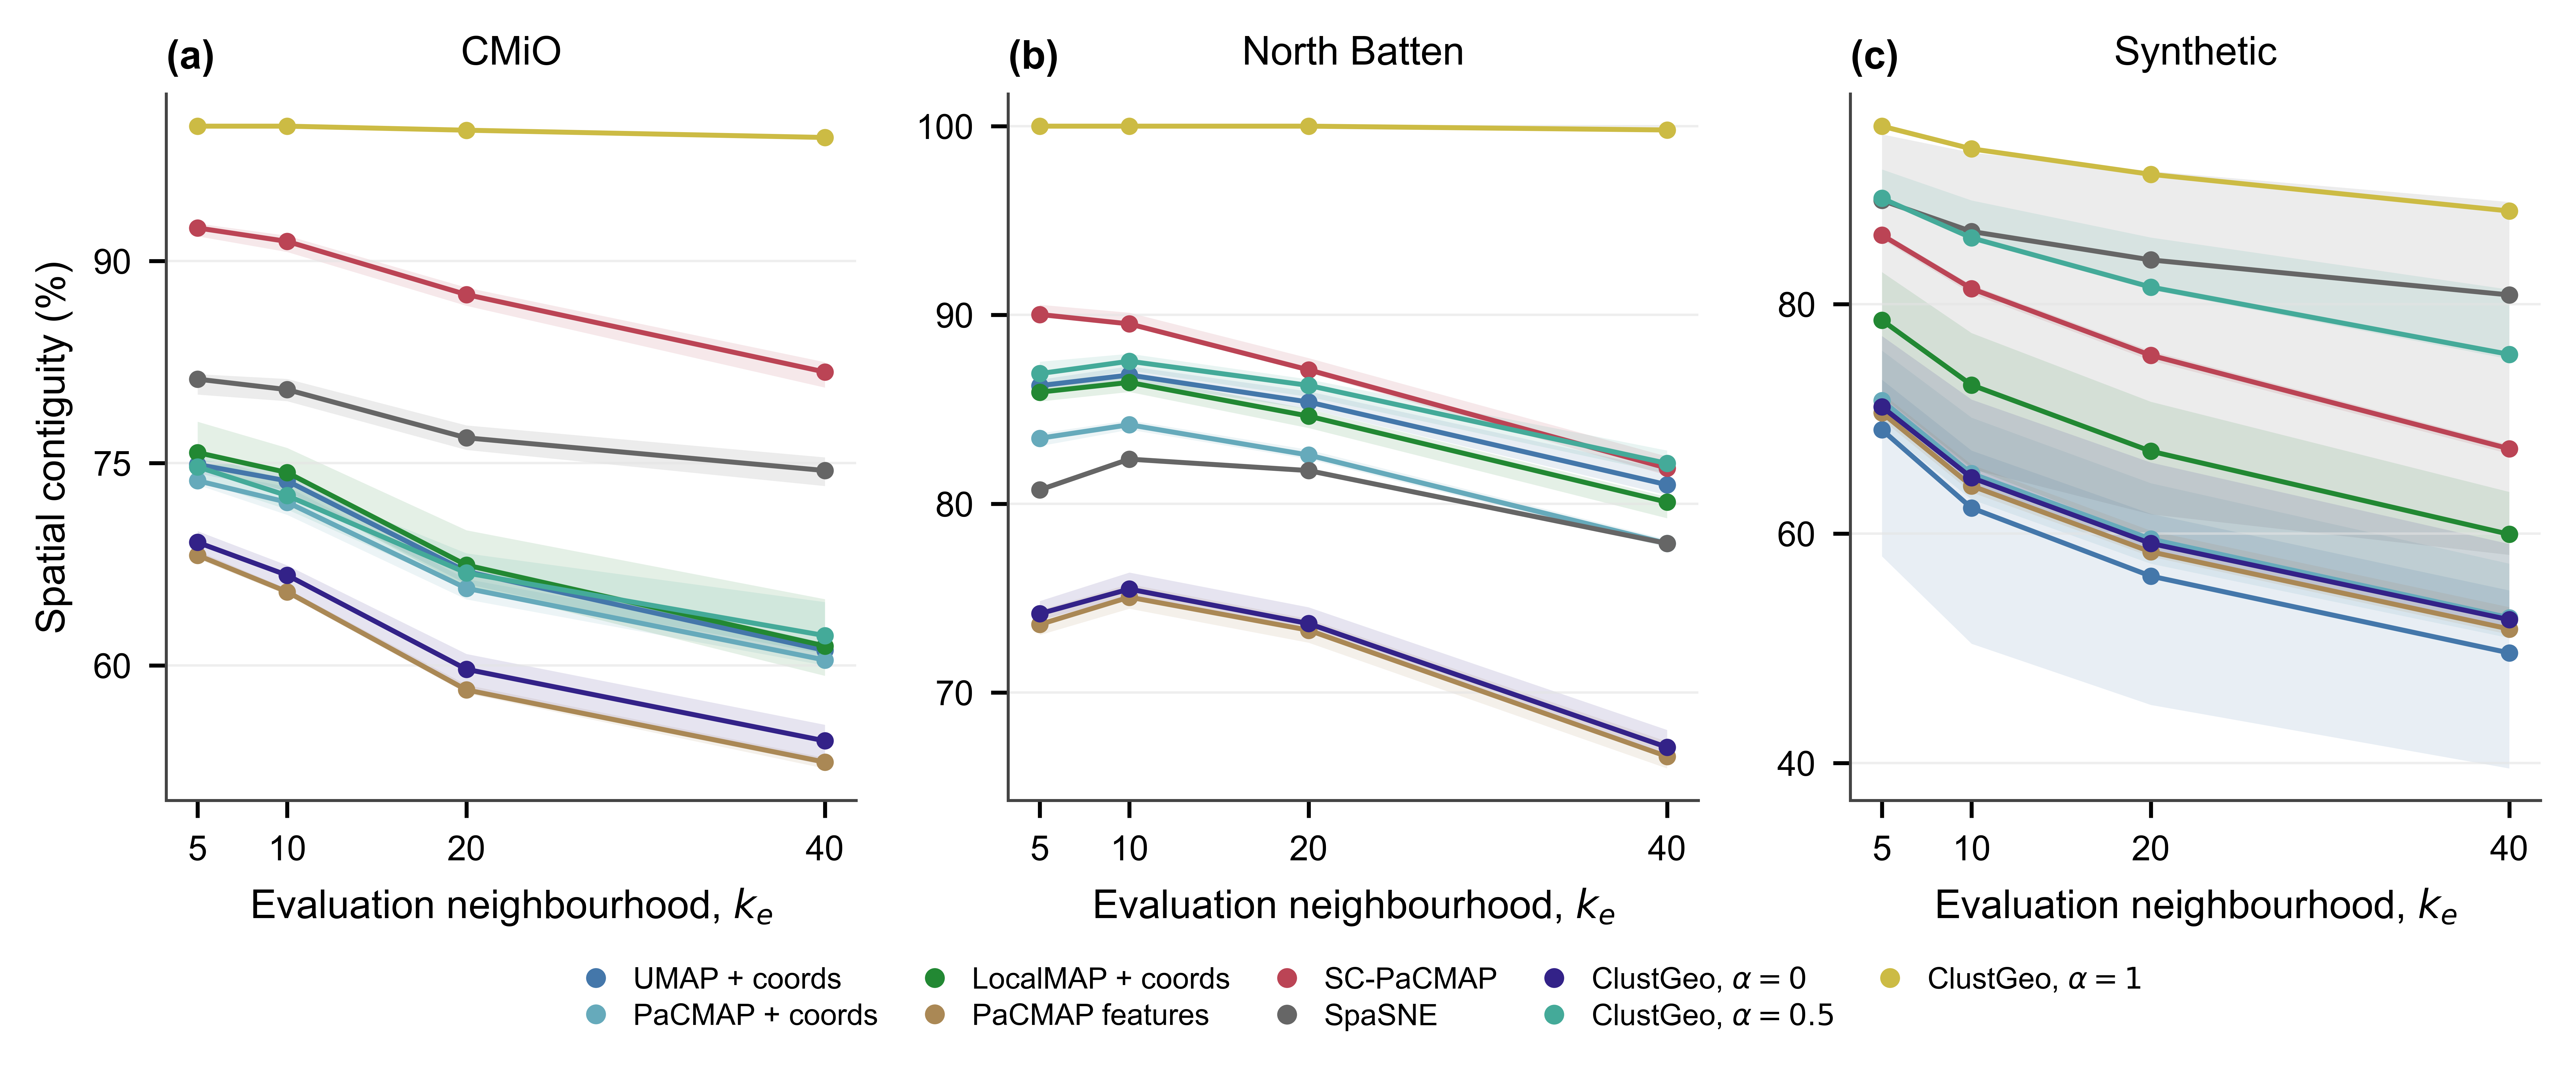

In [30]:
fig = plt.figure(figsize=(7.1, 2.9), layout='constrained')
grid = fig.add_gridspec(2, 3, height_ratios=[1, .12])
axes = [fig.add_subplot(grid[0, i]) for i in range(3)]
legend_ax = fig.add_subplot(grid[1, :])
legend_ax.set_axis_off()
for panel, (ax, dataset) in enumerate(zip(axes, DATASETS)):
    for method in METHOD_ORDER:
        summary = evaluation_scale_summary[(evaluation_scale_summary.dataset == dataset)
                  & (evaluation_scale_summary.method == method)].sort_values('k_e')
        ax.fill_between(summary.k_e, summary.q25, summary.q75,
                        color=COLORS[method], alpha=.12, linewidth=0)
        ax.plot(summary.k_e, summary['median'], color=COLORS[method],
                marker='o', markersize=2.5, linewidth=1.)
    panel_letter(ax, panel)
    ax.set_title(metadata[dataset]['dataset_title'], fontsize=8, pad=6)
    ax.set_xticks(EVALUATION_NEIGHBORS)
    ax.set_xlabel('Evaluation neighbourhood, $k_e$')
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.grid(axis='y', alpha=.6)
axes[0].set_ylabel('Spatial contiguity (%)')
legend_ax.legend(handles=compact_method_handles(), loc='center', ncol=5, fontsize=6,
                 columnspacing=.9, handletextpad=.25, labelspacing=.3, borderpad=0)
show_paper_figure(fig, 'evaluation_scale_three_datasets')


**Figure caption.** Evaluation-scale diagnostic: (a) CMiO, (b) North Batten, (c) Synthetic. Using partitions produced by the principal $k=10$ benchmark at the reference class counts $K=7,15,4$, spatial contiguity was recomputed at evaluation-neighbourhood sizes $k_e \in \{5,10,20,40\}$. The embeddings and cluster assignments were not refitted; only the raw-coordinate evaluation neighbourhood was changed. Lines show medians across 30 algorithm seeds and shaded bands show interquartile ranges. Colours identify the same benchmarks as in the performance plane. At every scale, spatial contiguity is $100[1-\overline H/\log(\min(K,k_e))]$. Axis limits adapt to each dataset.

## Table 3: Principal k = 10 benchmark across 30 algorithm seeds
Here $k=10$ is the fitting neighbourhood; K-means uses each dataset's reference class count $K=7,15,4$. Entries report **mean ± sample standard deviation** across seeds, calculated from unrounded values. SpaSNE contributes exactly 30 runs. All active benchmarks are included.

In [31]:
table_rows = []
for dataset in DATASETS:
    meta = metadata[dataset]
    principal = seed_metrics[dataset].loc[
        (seed_metrics[dataset].n_neighbors == PRINCIPAL_K)
        & (seed_metrics[dataset].K == meta['K_reference'])].copy()
    expected_methods = set(map(canonical_method, meta['methods']))
    if set(principal.method) != expected_methods:
        raise ValueError(f'{dataset}: incomplete principal benchmark methods.')
    check_seeds(principal, ['method'], meta['seeds'], dataset + ' Table 3')
    for method in METHOD_ORDER:
        part = principal[principal.method == method]
        if part.empty:
            continue
        row = {'dataset_id': dataset, 'Dataset': meta['dataset_title'],
               'method_id': method, 'Method': short_label(method).replace(' + coordinates',
                    ' + XY' if dataset == 'synthetic' else ' + XYZ'),
               'n_seeds': len(part), 'k': PRINCIPAL_K, 'K': meta['K_reference']}
        for metric in ('spatial_contiguity', 'multivariate_delineation', 'ARI'):
            row[f'{metric}_mean'] = part[metric].mean()
            row[f'{metric}_sd'] = part[metric].std(ddof=1)
        table_rows.append(row)

table3_numeric = pd.DataFrame(table_rows)
table3 = table3_numeric[['Dataset', 'Method']].copy()
for metric, label, decimals in [
    ('spatial_contiguity', 'Spatial contiguity (%)', 2),
    ('multivariate_delineation', 'Multivariate delineation (%)', 2),
    ('ARI', 'ARI', 3),
]:
    table3[label] = [f'{mean:.{decimals}f} ± {sd:.{decimals}f}'
                     for mean, sd in zip(table3_numeric[f'{metric}_mean'],
                                         table3_numeric[f'{metric}_sd'])]
caption = 'Table 3: Principal k = 10 benchmark across 30 algorithm seeds.'
table3_style = table3.style.hide(axis='index').set_caption(caption).set_properties(
    **{'font-family': 'Arial, sans-serif', 'font-size': '10pt', 'padding': '5px 8px'}
).set_table_styles([
    {'selector': 'caption', 'props': [('text-align', 'left'), ('font-weight', 'bold'), ('margin-bottom', '8px')]},
    {'selector': 'th', 'props': [('border-bottom', '1px solid #444'), ('text-align', 'left')]},
])
# Bold the SC-PaCMAP rows for easy comparison; this does not indicate significance.
sc_rows = table3_numeric.index[table3_numeric.method_id == PRIMARY]
table3_style = table3_style.set_properties(subset=pd.IndexSlice[sc_rows, :],
                                          **{'font-weight': 'bold'})
display(HTML(table3_style.to_html()))
if SAVE_OUTPUTS:
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    table3_numeric.to_csv(OUTPUT_ROOT / 'table3_principal_k10_numeric.csv', index=False)
    table3.to_csv(OUTPUT_ROOT / 'table3_principal_k10.csv', index=False)
    (OUTPUT_ROOT / 'table3_principal_k10.html').write_text(table3_style.to_html(), encoding='utf-8')
    (OUTPUT_ROOT / 'table3_principal_k10.tex').write_text(
        table3.to_latex(index=False, escape=True, caption=caption, label='tab:principal-k10'),
        encoding='utf-8')
print(f'Table 3: {len(table3)} rows; 30 seeds per method and dataset.')


Dataset,Method,Spatial contiguity (%),Multivariate delineation (%),ARI
CMiO,UMAP + XYZ,73.43 ± 1.49,40.16 ± 1.14,0.349 ± 0.022
CMiO,PaCMAP + XYZ,72.40 ± 1.84,41.51 ± 0.89,0.336 ± 0.019
CMiO,LocalMAP + XYZ,74.29 ± 3.07,35.72 ± 4.29,0.299 ± 0.041
CMiO,PaCMAP feature-only,65.48 ± 0.59,44.00 ± 0.54,0.277 ± 0.024
CMiO,SC-PaCMAP,91.28 ± 0.88,39.53 ± 0.25,0.531 ± 0.051
CMiO,SpaSNE,80.40 ± 0.95,41.29 ± 1.56,0.429 ± 0.023
CMiO,PaCMAP + ClustGeo (alpha=0),66.57 ± 1.31,43.33 ± 0.67,0.282 ± 0.022
CMiO,PaCMAP + ClustGeo (alpha=0.5),72.70 ± 1.84,41.80 ± 0.64,0.344 ± 0.035
CMiO,PaCMAP + ClustGeo (alpha=1),100.00 ± 0.00,27.80 ± 0.00,0.461 ± 0.000
North Batten,UMAP + XYZ,86.97 ± 0.70,29.74 ± 2.07,0.107 ± 0.008


Table 3: 27 rows; 30 seeds per method and dataset.
